# Low-code model comparison with PyCaret

PyCaret runs imputation, encoding, scaling and PCA inside its own pipeline and cross-validates every model on the
training split, so it is a quick cross-check on the hand-built pipelines in the other notebooks.

**Environment:** PyCaret 3.3 supports Python 3.9-3.11, so run this notebook in a separate environment
(`pip install pycaret`).

### Data preparation

* **The raw CSV is cleaned here:** stray tabs and spaces are stripped, and `pcv`, `wc` and `rc` are converted to
  numbers.
* **The `id` column is dropped.** The rows are sorted by class (ids 0-249 are CKD, 250-399 are not), so `id` alone
  would predict the label.
* **5% of the rows are kept unseen** until the very end, as a final check after tuning.
* Features are z-scored before PCA, so PCA is not dominated by the large-valued columns (`wc`, `bgr`).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
from pycaret.classification import (compare_models, create_model, plot_model, predict_model, pull, setup,
                                    tune_model)

In [2]:
def load_ckd(path="kidney_disease.csv"):
    """Load the UCI CKD data and repair its formatting problems."""
    df = pd.read_csv(path)
    for col in df.select_dtypes(include="object"):
        df[col] = df[col].str.strip()                     # 'ckd\t', '\tno', ' yes'
    for col in ["pcv", "wc", "rc"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")  # '\t?' -> NaN
    return df


dataset = load_ckd().drop(columns="id")
dataset["CKD"] = (dataset.pop("classification") == "ckd").astype(int)   # 1 = CKD
print(dataset.shape)
dataset.head()

(400, 25)


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,CKD
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,...,44.0,7800.0,5.2,yes,yes,no,good,no,no,1
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,...,38.0,6000.0,NaN,no,no,no,good,no,no,1
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,...,31.0,7500.0,NaN,no,yes,no,poor,no,yes,1
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,...,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,1
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,...,35.0,7300.0,4.6,no,no,no,good,no,no,1


In [3]:
# Keep 5% of the rows completely unseen until the very end.
data = dataset.sample(frac=0.95, random_state=786)
data_unseen = dataset.drop(data.index)
data, data_unseen = data.reset_index(drop=True), data_unseen.reset_index(drop=True)
print("modelling data:", data.shape, "| unseen:", data_unseen.shape,
      "| CKD in unseen:", int(data_unseen.CKD.sum()), "of", len(data_unseen))

modelling data: (380, 25) | unseen: (20, 25) | CKD in unseen: 11 of 20


## Setup

PyCaret splits the modelling data 70/30 (stratified), imputes (mean / mode), one-hot encodes the categorical
columns, z-scores, and keeps the principal components that explain 95% of the variance. Every step is fitted on the
training part only and re-fitted inside each of the 10 cross-validation folds.

In [4]:
exp = setup(data=data, target="CKD", session_id=124, normalize=True, pca=True, pca_components=0.95, verbose=True)

,Description,Value
0,Session id,124
1,Target,CKD
2,Target type,Binary
3,Original data shape,"(380, 25)"
4,Transformed data shape,"(380, 20)"
5,Transformed train set shape,"(266, 20)"
6,Transformed test set shape,"(114, 20)"
7,Numeric features,14
8,Categorical features,10
9,Rows with missing values,60.8%


## Compare models (10-fold CV on the 70% training split)

In [5]:
best = compare_models()
comparison = pull()

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
rf,Random Forest Classifier,0.9963,0.9994,0.9941,1.0000,0.9970,0.9922,0.9925,0.1040
et,Extra Trees Classifier,0.9926,1.0000,0.9882,1.0000,0.9939,0.9844,0.9850,0.0950
nb,Naive Bayes,0.9889,1.0000,0.9824,1.0000,0.9909,0.9767,0.9775,0.0480
gbc,Gradient Boosting Classifier,0.9889,0.9885,0.9882,0.9944,0.9911,0.9763,0.9772,0.0750
lr,Logistic Regression,0.9887,1.0000,0.9824,1.0000,0.9909,0.9762,0.9770,2.7300
svm,SVM - Linear Kernel,0.9887,1.0000,0.9941,0.9886,0.9911,0.9758,0.9767,0.0460
dt,Decision Tree Classifier,0.9850,0.9841,0.9882,0.9886,0.9881,0.9680,0.9692,0.0440
ada,Ada Boost Classifier,0.9850,0.9926,0.9882,0.9886,0.9881,0.9680,0.9692,0.0750
knn,K Neighbors Classifier,0.9776,0.9941,0.9643,1.0000,0.9812,0.9537,0.9563,2.0810
qda,Quadratic Discriminant Analysis,0.9623,0.9976,0.9397,1.0000,0.9685,0.9215,0.9253,0.0460


## Linear discriminant analysis

A random forest scores best in the comparison above. LDA is a much simpler linear model; the next cells tune it and
check how close it gets on the hold-out and unseen rows.

In [6]:
lda = create_model("lda")

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9259,1.0000,0.8824,1.0000,0.9375,0.8475,0.8575
1,0.9259,1.0000,0.8824,1.0000,0.9375,0.8475,0.8575
2,0.9259,1.0000,0.8824,1.0000,0.9375,0.8475,0.8575
3,0.9630,1.0000,0.9412,1.0000,0.9697,0.9222,0.9250
4,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
5,0.9259,1.0000,0.8824,1.0000,0.9375,0.8475,0.8575
6,0.9615,0.9412,0.9412,1.0000,0.9697,0.9172,0.9204
7,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
8,0.8462,0.9812,0.7500,1.0000,0.8571,0.6977,0.7319


In [7]:
tuned_lda = tune_model(lda)

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9259,1.0000,0.8824,1.0000,0.9375,0.8475,0.8575
1,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
2,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
3,0.9630,1.0000,0.9412,1.0000,0.9697,0.9222,0.9250
4,0.9630,1.0000,0.9412,1.0000,0.9697,0.9222,0.9250
5,0.9259,1.0000,0.8824,1.0000,0.9375,0.8475,0.8575
6,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
7,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
8,0.9231,1.0000,0.8750,1.0000,0.9333,0.8434,0.8539


Fitting 10 folds for each of 10 candidates, totalling 100 fits


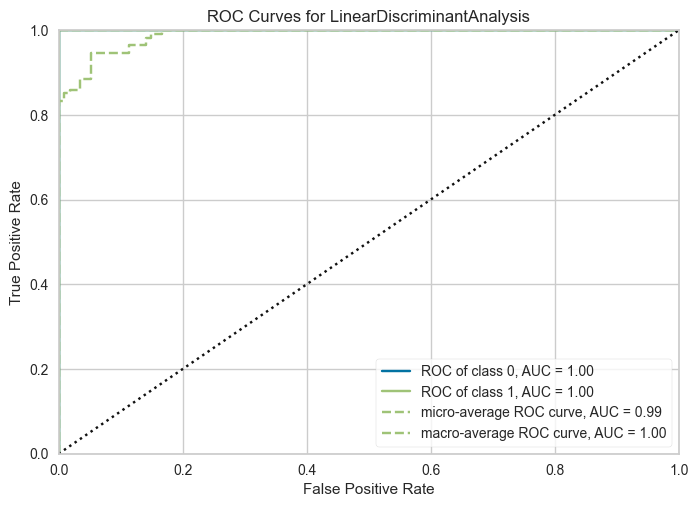

In [8]:
plot_model(tuned_lda, plot="auc")

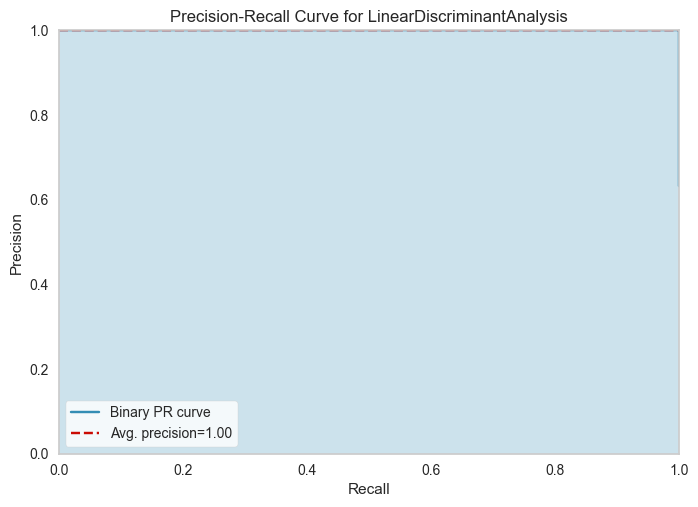

In [9]:
plot_model(tuned_lda, plot="pr")

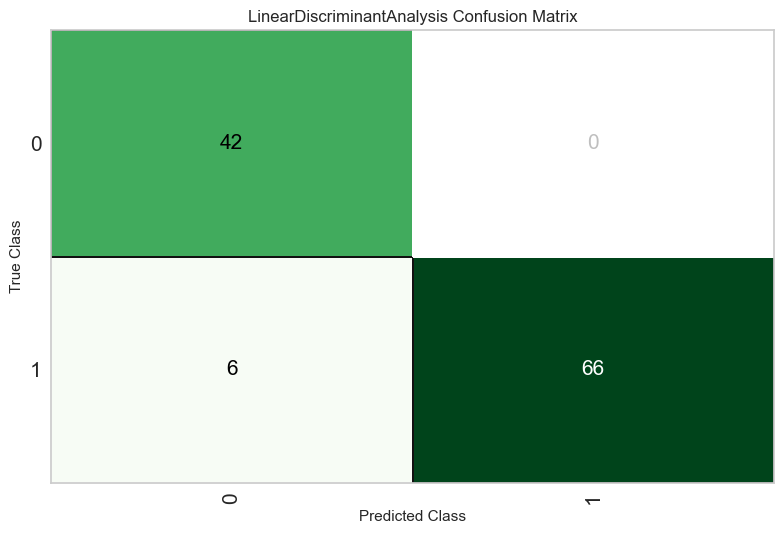

In [10]:
plot_model(tuned_lda, plot="confusion_matrix")

## Hold-out (30% split) and unseen data

In [11]:
holdout_predictions = predict_model(tuned_lda)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Linear Discriminant Analysis,0.9474,1.0000,0.9167,1.0000,0.9565,0.8902,0.8956


In [12]:
unseen_predictions = predict_model(tuned_lda, data=data_unseen)
unseen_scores = pull()
unseen_scores

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Linear Discriminant Analysis,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Linear Discriminant Analysis,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [13]:
best_holdout = predict_model(best)
print("best model from compare_models():", type(best).__name__)

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Random Forest Classifier,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000


best model from compare_models(): RandomForestClassifier
